<a href="https://colab.research.google.com/github/AK888-hp/ML-II_Lab/blob/main/baggingboosting.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### 1. Training with a Seaborn Diamonds dataset
We will now load the `diamonds` dataset, clean it, encode its categorical columns, and split it for training and testing.

In [ ]:
# Load the diamonds dataset
df_diamonds = sns.load_dataset('diamonds')
print("Original Diamonds Dataset Shape:", df_diamonds.shape)
display(df_diamonds.head())

# Drop missing values if any
df_diamonds = df_diamonds.dropna()

# Encode categorical features ('color', 'clarity')
le_color = LabelEncoder()
df_diamonds['color'] = le_color.fit_transform(df_diamonds['color'])

le_clarity = LabelEncoder()
df_diamonds['clarity'] = le_clarity.fit_transform(df_diamonds['clarity'])

# Target is 'cut' (ordinal quality rating)
X_large = df_diamonds.drop(columns=['cut'])
y_large = df_diamonds['cut']

# To keep training fast while using a much larger dataset, we will sample 15,000 instances
df_sampled = df_diamonds.sample(n=15000, random_state=42)
X_large = df_sampled.drop(columns=['cut'])
y_large = df_sampled['cut']

# Split into training and test sets
X_train_l, X_test_l, y_train_l, y_test_l = train_test_split(X_large, y_large, test_size=0.2, random_state=42, stratify=y_large)
print(f"New Larger Dataset - Train Size: {X_train_l.shape[0]}, Test Size: {X_test_l.shape[0]}")

Original Diamonds Dataset Shape: (53940, 10)


,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75


New Larger Dataset - Train Size: 12000, Test Size: 3000


### 6. Bagging vs Boosting on Larger Dataset

In [ ]:
# 1. Bagging (Random Forest)
rf_large = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf_large.fit(X_train_l, y_train_l)
y_pred_rf_l = rf_large.predict(X_test_l)
rf_acc_l = accuracy_score(y_test_l, y_pred_rf_l)

print("=== Bagging (Random Forest) on Large Dataset ===")
print(f"Accuracy: {rf_acc_l:.4f}")
print(classification_report(y_test_l, y_pred_rf_l))

=== Bagging (Random Forest) on Large Dataset ===
Accuracy: 0.7520
              precision    recall  f1-score   support

        Fair       0.92      0.89      0.90        90
        Good       0.72      0.63      0.68       282
       Ideal       0.81      0.92      0.86      1201
     Premium       0.71      0.79      0.75       767
   Very Good       0.64      0.44      0.52       660

    accuracy                           0.75      3000
   macro avg       0.76      0.73      0.74      3000
weighted avg       0.74      0.75      0.74      3000



In [ ]:
# 2. Boosting (Gradient Boosting)
gb_large = GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, random_state=42)
gb_large.fit(X_train_l, y_train_l)
y_pred_gb_l = gb_large.predict(X_test_l)
gb_acc_l = accuracy_score(y_test_l, y_pred_gb_l)

print("=== Boosting (Gradient Boosting) on Large Dataset ===")
print(f"Accuracy: {gb_acc_l:.4f}")
print(classification_report(y_test_l, y_pred_gb_l))

=== Boosting (Gradient Boosting) on Large Dataset ===
Accuracy: 0.7460
              precision    recall  f1-score   support

        Fair       0.92      0.92      0.92        90
        Good       0.78      0.61      0.68       282
       Ideal       0.81      0.92      0.86      1201
     Premium       0.67      0.85      0.75       767
   Very Good       0.66      0.35      0.46       660

    accuracy                           0.75      3000
   macro avg       0.77      0.73      0.73      3000
weighted avg       0.74      0.75      0.73      3000



,Model,Accuracy
0,Bagging (Random Forest),0.752
1,Boosting (Gradient Boosting),0.746


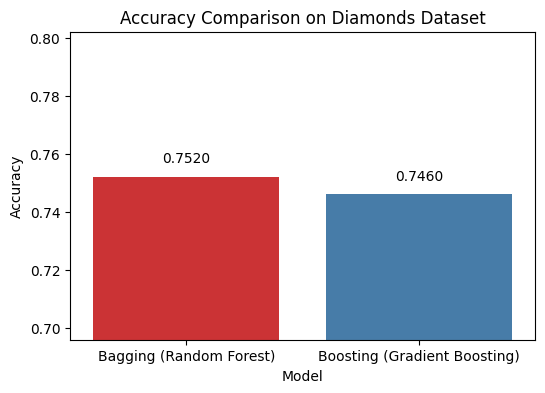

In [ ]:
# Compare and visualize results on the larger dataset
large_results = pd.DataFrame({
    'Model': ['Bagging (Random Forest)', 'Boosting (Gradient Boosting)'],
    'Accuracy': [rf_acc_l, gb_acc_l]
})

display(large_results)

plt.figure(figsize=(6, 4))
sns.barplot(x='Model', y='Accuracy', hue='Model', data=large_results, palette='Set1', legend=False)
plt.ylim(min(rf_acc_l, gb_acc_l) - 0.05, max(rf_acc_l, gb_acc_l) + 0.05)
plt.title('Accuracy Comparison on Diamonds Dataset')
plt.ylabel('Accuracy')
for index, row in large_results.iterrows():
    plt.text(index, row['Accuracy'] + 0.005, f"{row['Accuracy']:.4f}", color='black', ha="center")
plt.show()